# DX603 — Homework 09: Neural Networks for Regression

#### Due Date: Sunday, November 1st at 11:59pm (with 2 hour plus 1 minute grace period)

#### The late policy is described in the DX 603 Syllabus.

### Introduction

This assignment adapts the **batch-size and learning-rate investigations from DX703 Homework 02** to the **California Housing regression** dataset. The first problem introduces Keras regression; subsequent problems examine the training process. We will study early stopping, regularization, dropout, and generalization techniques more fully in Week 10.

**Submission convention:** Complete the computational problems, set the specified `a...` answer variables using *expressions* derived from your results, and run every **Graded Answer** cell. Multiple-choice answers and reflections follow the same format as recent DX603 homeworks.

**Prediction task:** Estimate median house value, measured in units of **$100,000**. Models train using mean squared error (MSE) loss; **MAE** is our main evaluation metric (lower is better). Keep the held-out test data untouched until Problem 5.

**Grading:** Coding 80 points; multiple choice 10 points; reflections 10 points. **Total: 100 points.**

In [87]:

# Force TensorFlow to use CPU only
# Must run BEFORE importing TensorFlow or Keras

import os

os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

# Reproducibility
os.environ["PYTHONHASHSEED"] = "42"
os.environ["TF_DETERMINISTIC_OPS"] = "1"

import tensorflow as tf

tf.config.set_visible_devices([], "GPU")
tf.keras.utils.set_random_seed(42)

print("TensorFlow version:", tf.__version__)
print("Visible GPUs:", tf.config.get_visible_devices("GPU"))


TensorFlow version: 2.21.0
Visible GPUs: []


In [88]:
# Imports and reproducibility
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import models, layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input,Dense

RANDOM_SEED = 42
tf.keras.utils.set_random_seed(RANDOM_SEED)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## Provided setup — California Housing

The dataset contains **20,640 observations** with **8 numerical predictors**. Its target is median house value in units of $100,000. We supply the loading, 80/10/10 splitting, and training-only feature standardization so you can focus on neural networks. In California Housing, the target has an upper cap; keep that limitation in mind when interpreting errors.

In [89]:

# Load the California Housing dataset
housing = fetch_california_housing(as_frame=True)

X = housing.data.copy()
y = housing.target.copy()

# Split into training (80%), validation (10%), and test (10%)
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.10, random_state=RANDOM_SEED
)

X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=1/9, random_state=RANDOM_SEED
)

# Fit the scaler on training data only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train).astype("float32")

# Apply the same transformation to validation and test data
X_val_scaled = scaler.transform(X_val).astype("float32")
X_test_scaled = scaler.transform(X_test).astype("float32")

# Convert targets to float32 for Keras
y_train_arr = y_train.to_numpy(dtype="float32")
y_val_arr = y_val.to_numpy(dtype="float32")
y_test_arr = y_test.to_numpy(dtype="float32")

print("Training:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Test:", X_test_scaled.shape)
print("Target range (training):", float(y_train.min()), float(y_train.max()))

display(X.head())


Training: (16512, 8)
Validation: (2064, 8)
Test: (2064, 8)
Target range (training): 0.14999 5.00001


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [90]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
dtypes: float64(8)
memory usage: 1.3 MB


In [91]:
X.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000


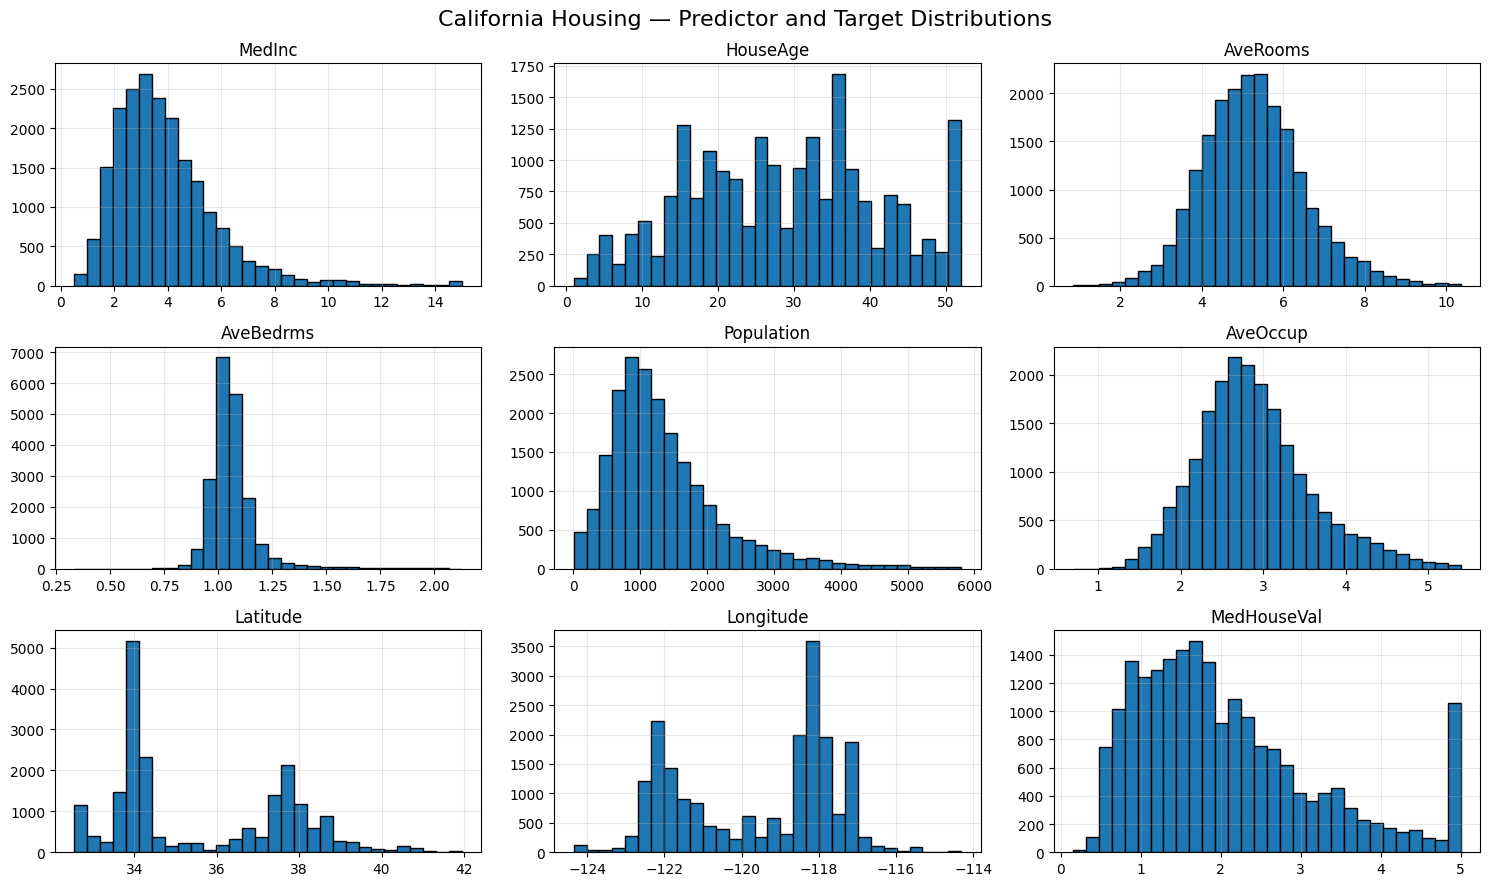

In [92]:

# Histograms of all eight predictors and the target
# For strongly skewed predictors, display values up to the 99th percentile

skewed_features = ["AveRooms", "AveBedrms", "Population", "AveOccup"]

# Combine predictors and target for visualization only
plot_data = X.copy()
plot_data["MedHouseVal"] = y

fig, axes = plt.subplots(3, 3, figsize=(15, 9))

for ax, column in zip(axes.flat, plot_data.columns):
    values = plot_data[column].dropna()

    if column in skewed_features:
        upper = values.quantile(0.99)
        values = values[values <= upper]

    ax.hist(values, bins=30, edgecolor="black")
    ax.set_title(column)
    ax.grid(alpha=0.3)

plt.suptitle("California Housing — Predictor and Target Distributions",
             fontsize=16)
plt.tight_layout()
plt.show()


**A Note About the Target Variable**

The California Housing dataset records median house values in units of $\$100,000,$ with values capped at approximately $\$500,000.$ This explains the unusually large spike at the upper end of the target histogram.

Because the true values of more expensive districts are unknown, we will **retain these observations rather than remove or modify them**. However, the cap limits what our regression model can learn about high-value districts and should be kept in mind when interpreting prediction errors.

For this homework, our primary goal is to understand how neural networks are trained, rather than to develop a perfect housing valuation model.

#### Utility code for plotting results

In [93]:
# Utility function: Plotting Training and Validation MSE and MAE
# Takes the history object returned by fit

def plot_history(history):
    n_epochs = len(history.history['loss'])
    epochs = range(1, n_epochs + 1)

    plt.figure(figsize=(7, 8))

    # MSE
    plt.subplot(2, 1, 1)
    plt.plot(epochs, history.history['loss'],
             label='Training MSE', color='tab:red')
    plt.plot(epochs, history.history['val_loss'],
             label='Validation MSE', color='tab:red', linestyle='--')
    plt.ylabel('MSE')
    plt.title('Training and Validation Loss (MSE)')
    plt.grid(True)
    plt.legend()

    # MAE
    plt.subplot(2, 1, 2)
    plt.plot(epochs, history.history['mae'],
             label='Training MAE', color='tab:blue')
    plt.plot(epochs, history.history['val_mae'],
             label='Validation MAE', color='tab:blue', linestyle='--')
    plt.xlabel('Epoch')
    plt.ylabel('MAE')
    plt.title('Training and Validation MAE')
    plt.grid(True)
    plt.legend()

    plt.tight_layout()
    plt.show()



In [94]:
def plot_comparison(histories, title, detail_ylim=None):
    """Compare training and validation MSE across experiments."""

    fig, ax = plt.subplots(figsize=(9, 5))

    for setting, history in histories.items():
        epochs = range(1, len(history.history["loss"]) + 1)

        line, = ax.plot(
            epochs, history.history["loss"],
            label=f"{setting} — Training"
        )

        ax.plot(
            epochs, history.history["val_loss"],
            color=line.get_color(),
            linestyle="--",
            label=f"{setting} — Validation"
        )

    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE")
    ax.set_title(title)

    if detail_ylim is not None:
        ax.set_ylim(*detail_ylim)

    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()


## Problem 1 — Build, Compile, Train, and Evaluate a Regression Network [20 points]

In this problem, you will build your first neural network for regression using the California Housing dataset. You will construct, compile, train, and evaluate a Keras `Sequential` model.


1. **Build the model**
   - Use two hidden `Dense` layers with 64 and 32 neurons.
   - Use `relu` activation for both hidden layers.
   - Use **one output neuron with linear activation**, appropriate for regression.
   - Display the architecture using `model.summary()`.

2. **Compile the model**
   - Use the following settings:

   ```python
           optimizer = Adam(learning_rate=0.001)
           loss      = "mse"
           metrics   = ["mae"]
   ```

3. **Train the model**
   - Train for **50 epochs**.
   - Use a `batch_size` of **64**.
   - Use the provided training data and fixed validation set.
   - Set `verbose=0` to suppress epoch-by-epoch output.

4. **Examine training and validation performance**
   - Plot the MSE loss and MAE curves using `plot_history()`.
   - Evaluate the final trained model on both the training and validation sets.
   - Report training and validation MAE.
   - Remember that house values are measured in units of $100,000.

### Graded Answers

Set the following variables using the model and results from Part A:

- `a1a`: **Training MAE** of the final trained model.
- `a1b`: **Validation MAE** of the final trained model.
- `a1c`: **Number of trainable parameters** in the first hidden `Dense` layer.

Use **computed expressions or variables** rather than manually entering numerical results. For the MAE answers, use values obtained by evaluating the final trained model, rather than the last entries in the training history.

Be sure to run all the **Graded Answer** cells before submitting.


In [95]:
# Your code here; add additional cells as needed

# Part 1
num_features = X_train_scaled.shape[1]

tf.keras.utils.set_random_seed(RANDOM_SEED)

baseline_model = models.Sequential([
    layers.Input(shape=(num_features,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="linear")  # Output Layer
])

baseline_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,689 (10.50 KB)

 Trainable params: 2,689 (10.50 KB)

 Non-trainable params: 0 (0.00 B)

In [96]:
# Part 2
opt = Adam(learning_rate=0.001)

baseline_model.compile(loss='mse',
               optimizer=opt,
               metrics=['mae'])

# Part 3
epochs = 50
batch_size = 64

baseline_history = baseline_model.fit(
    X_train_scaled,
    y_train_arr,
    validation_data=(X_val_scaled,y_val_arr),
    epochs=epochs,
    batch_size=batch_size,
    verbose=0
)

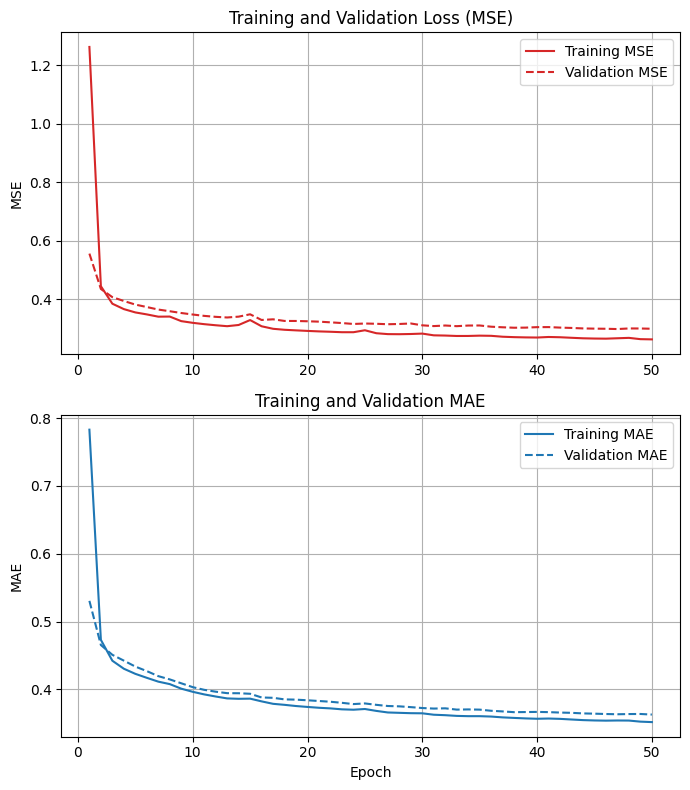

In [97]:
# Part 4
plot_history(baseline_history)

training_results = baseline_model.evaluate(X_train_scaled, y_train_arr, verbose=0)
validation_results = baseline_model.evaluate(X_val_scaled, y_val_arr, verbose=0)

#### Problem 1 Graded Answers 

In [98]:
 # Your answer here

a1a = training_results[1]                    # replace 0 with an expression or variable returning the Training MAE of the final trained model.

In [99]:
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1a = {a1a:.4f}")

a1a = 0.3477


In [100]:
 # Your answer here

a1b = validation_results[1]                    # replace 0 with an expression or variable returning the Validation MAE of the final trained model.

In [101]:
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1b = {a1b:.4f}")

a1b = 0.3627


In [102]:
 # Your answer here

a1c = baseline_model.layers[1].count_params()                    # replace 0 with an expression or integer for the number of trainable parameters in the first hidden Dense layer.

In [103]:
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1c = {a1c}")

a1c = 2080


## Problem 2 — Examine Predictions and Training History [15 points]

In Problem 1, you trained a neural network to predict median house values. In this problem, you will examine its predictions and investigate how its performance changed during training.

### Part A: Examine Predictions and Training History

1. **Examine validation predictions**
   - Use `baseline_model` to predict house values for the validation set.
   - Create a scatterplot of **predicted versus actual values**, with actual values on the horizontal axis and predicted values on the vertical axis.
   - Include a diagonal reference line representing perfect predictions.
   - Look for patterns that might indicate systematic prediction errors.

2. **Examine the training history**
   - Use `baseline_history` to find the epoch with the **lowest validation MSE**.
   - Report the validation MSE at that epoch and at the final epoch.
   - Remember that Python indexing begins at 0, but epochs are numbered starting at 1.

3. **Compare the results**
   - Determine whether the lowest validation MSE occurred at the final epoch or earlier.
   - Consider what this difference suggests about training for a fixed number of epochs.

**Do not retrain or modify the model, and do not use the test set.**

### Part B: Problem 2 Graded Answers

Set the following variables using the training history from Problem 1:

- `a2a`: **Epoch number** at which the lowest validation MSE occurred (starting at 1).
- `a2b`: **Lowest validation MSE** observed during training.
- `a2c`: **Validation MSE at the final epoch**.

Use **computed expressions or variables** rather than manually entering numerical results. Obtain all three answers from `baseline_history.history`.

Be sure to run all the **Graded Answer** cells before submitting.

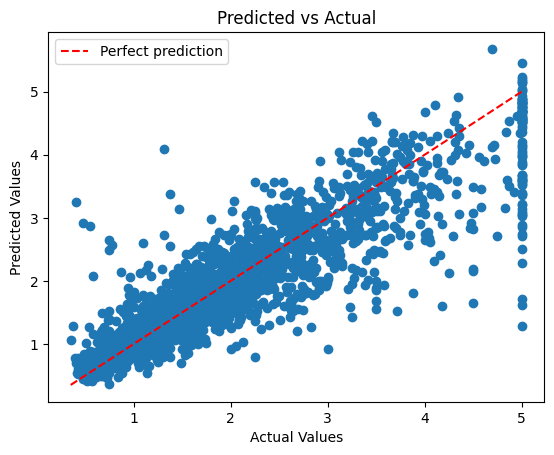

In [104]:
# Your code here; add additional cells as needed

# Part 1
samples = X_val_scaled

base_preds = baseline_model.predict(samples, verbose=0)

low, high = y_val_arr.min(), y_val_arr.max()
plt.scatter(x=y_val_arr, y=base_preds.ravel())
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Predicted vs Actual")
plt.plot([low, high], [low, high], color="red", linestyle="--", label="Perfect prediction")
plt.legend()
plt.show()

In [105]:
# Part 2
val_mse_epoch = np.argmin(baseline_history.history["val_loss"])+1


#### Problem 2 Graded Answers 

In [106]:
 # Your answer here

a2a = np.argmin(baseline_history.history["val_loss"])+1                   # replace 0 with an expression or integer returning the epoch number at which the lowest validation MSE occurred (starting at 1).

In [107]:
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2a = {a2a}")

a2a = 47


In [108]:
 # Your answer here

a2b = np.min(baseline_history.history["val_loss"])                    # replace 0 with an expression or float returning the lowest validation MSE observed during training.

In [109]:
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2b = {a2b:.4f}")

a2b = 0.2974


In [110]:
 # Your answer here

a2c = baseline_history.history["val_loss"][-1]                    # replace 0 with an expression or float for the validation MSE at the final epoch.

In [111]:
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2c = {a2c:.4f}")

a2c = 0.2984


## Problem 3 — Mini-Batch Size Experiments [20 points]

In Problem 1, you trained a neural network using a mini-batch size of 64. In this problem, you will investigate how changing the mini-batch size affects training behavior, predictive performance, and computational cost.

### Train and Compare Four Batch Sizes

Train four new networks using batch sizes of **2, 4, 8, and 16**.

1. **Build and compile the models**
   - Use the same architecture as Problem 1: two hidden `Dense` layers with 64 and 32 ReLU neurons, followed by one linear output neuron.
   - Use `Adam(learning_rate=0.001)`, MSE loss, and MAE as a metric.
   - Start each experiment with a **newly initialized model**, resetting the random seed to `42` before constructing it.

2. **Train the models**
   - Train each model for **50 epochs** using its assigned batch size.
   - Use the same training and validation partitions.
   - Set `verbose=0`.
   - Record the wall-clock training time for each experiment using `time.perf_counter()`.
   - Save the `History` object returned by `model.fit()` for each experiment.

3. **Compare the results**
   - Evaluate each trained model on the training and validation sets.
   - Create a table reporting batch size, training MAE, validation MAE, and training time in seconds.
   - Plot **both training and validation MSE** for all four experiments using the provided `plot_comparison()` function.

   To use `plot_comparison()`, create a dictionary whose keys are the batch sizes and whose values are the corresponding training histories. For example, if your dictionary is named `batch_histories`, call:

   ```python
   plot_comparison(
       batch_histories,
       "Effect of Mini-Batch Size on Training and Validation"
   )
   ```

   The function plots all experiments on the same axes, using solid lines for training MSE and dashed lines for validation MSE.

   - Create a second plot showing **validation MAE versus training time**, using training time (seconds) on the horizontal axis and validation MAE on the vertical axis.
   - Use a scatterplot, without connecting lines, and label each point with its batch size.
   - Remember that lower validation MAE and shorter training time are both desirable.

4. **Examine the effects of batch size**
   - Identify which batch size achieved the lowest validation MAE.
   - Compare how batch size affects the speed and smoothness of training, the final validation performance, and computational time.
   - Examine the training and validation curves. Do the models with lower training loss also achieve lower validation loss?
   - Compare the improvements in validation MAE against the additional training time. Are the improvements always worth the computational cost?
   - Suppose prediction accuracy were your primary concern. Which batch size would you recommend? Would you make the same choice if computational efficiency were more important? Justify your answers using your results.

5. **Consider the experimental design**

   All four models were trained for the same number of epochs, but a smaller mini-batch produces more weight updates per epoch.

   - Did the four models receive the same number of weight updates?
   - How might this difference affect your interpretation of the results?
   - Would the same batch size necessarily perform best if the models were trained for a different number of epochs?

**Important:** Change only the batch size between experiments. Do not continue training an earlier model or use the test set. Training times will depend on your computer, and a smaller batch size is not necessarily better.

### Graded Answers

Set the following variables using your results from Part A:

- `a3a`: **Batch size** that achieved the lowest validation MAE.
- `a3b`: **Lowest validation MAE** among the four experiments.

Use computed expressions or variables rather than manually entering numerical results.

Be sure to run all the **Graded Answer** cells before submitting.


In [141]:
# Your code here; add additional cells as needed
from tensorflow.keras.models import clone_model

batch_sizes = [2,4,8,16]
histories = {}
batch_results = []

for batch in batch_sizes:

    tf.keras.utils.set_random_seed(RANDOM_SEED)
    batch_model = clone_model(baseline_model)
    batch_opt = Adam(learning_rate=0.001)

    batch_model.compile(loss='mse',
               optimizer=batch_opt,
               metrics=['mae'])

    epochs = 50
    batch_size = batch

    start = time.perf_counter()

    batch_history = batch_model.fit(
        X_train_scaled,
        y_train_arr,
        validation_data=(X_val_scaled,y_val_arr),
        epochs=epochs,
        batch_size=batch_size,
        verbose=0
    )

    elapsed = time.perf_counter() - start

    histories[batch] = batch_history

    training_results = batch_model.evaluate(X_train_scaled, y_train_arr, verbose=0)
    validation_results = batch_model.evaluate(X_val_scaled, y_val_arr, verbose=0)

    batch_results.append({
    "batch_size": batch,
    "train_mae": training_results[1],
    "val_mae":   validation_results[1],
    "time_s":    elapsed,
})

batch_results

[{'batch_size': 2,
  'train_mae': 0.3214307129383087,
  'val_mae': 0.34029263257980347,
  'time_s': 1034.959846300073},
 {'batch_size': 4,
  'train_mae': 0.32216501235961914,
  'val_mae': 0.3473993241786957,
  'time_s': 475.6582431999268},
 {'batch_size': 8,
  'train_mae': 0.32415199279785156,
  'val_mae': 0.3441365361213684,
  'time_s': 223.57667920005042},
 {'batch_size': 16,
  'train_mae': 0.33239492774009705,
  'val_mae': 0.3524477183818817,
  'time_s': 99.61592140002176}]

#### Problem 3 Graded Answers 

In [144]:
 # Your answer here
batch_results1 = pd.DataFrame(batch_results)

best_val_mae_row = batch_results1['val_mae'].idxmin()

a3a = batch_results1.loc[best_val_mae_row, "batch_size"]                    # replace 0 with an expression or integer returning the batch size that achieved the lowest validation MAE.

In [145]:
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a3a = {a3a}")

a3a = 2


In [146]:
 # Your answer here

best_val_mae_value = np.min(batch_results1['val_mae'])

a3b = best_val_mae_value                    # replace 0 with an expression or float returning the lowest validation MAE among the three experiments.

In [147]:
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a3b = {a3b:.4f}")

a3b = 0.3403


## Problem 4 — Learning-Rate Experiments [20 points]

In Problem 3, you investigated how mini-batch size affects neural-network training and selected the batch size that achieved the lowest validation MAE. In this problem, you will **use that selected batch size** while investigating how the learning rate affects the speed and stability of training and the resulting predictive performance.

This is an example of **sequential hyperparameter tuning**: first select a batch size, then investigate learning rates while holding that batch size fixed.

### Train and Compare Three Learning Rates

Train three new networks using Adam learning rates of **0.0001, 0.001, and 0.01**, with the batch size selected in Problem 3 (`a3a`).

1. **Build and compile the models**
   - Use the same architecture as Problem 1: two hidden `Dense` layers with 64 and 32 ReLU neurons, followed by one linear output neuron.
   - Use MSE loss and MAE as a metric.
   - Set the Adam learning rate to `0.0001`, `0.001`, or `0.01`.
   - Start each experiment with a **newly initialized model**, resetting the random seed to `42` before constructing it.

2. **Train the models**
   - Train each model for **50 epochs**, using the batch size selected in Problem 3 (`a3a`).
   - Use the same batch size for all three experiments. **Change only the learning rate.**
   - Use the same training and validation partitions.
   - Set `verbose=0`.
   - Save the `History` object returned by `model.fit()` for each experiment.

   For example, use the following argument when calling `model.fit()`:

   ```python
   batch_size=int(a3a)
   ```

3. **Compare the results**
   - Evaluate each trained model on the training and validation sets.
   - Create a table reporting the learning rate, training MAE, and validation MAE.
   - Plot **both training and validation MSE** for all three experiments using the provided `plot_comparison()` function.

   To use `plot_comparison()`, create a dictionary whose keys are the learning rates and whose values are the corresponding training histories. For example, if your dictionary is named `lr_histories`, call:

   ```python
   plot_comparison(
       lr_histories,
       "Effect of Learning Rate on Training and Validation"
   )
   ```

   The function plots all experiments on the same axes, using solid lines for training MSE and dashed lines for validation MSE.

   Because the learning rates may produce substantially different initial losses, you may also use the optional `detail_ylim` parameter to examine the lower portion of the curves:

   ```python
   plot_comparison(
       lr_histories,
       "Effect of Learning Rate — Detail",
       detail_ylim=(0.2, 0.8)
   )
   ```

4. **Examine the effects of learning rate**
   - Identify which learning rate achieved the lowest validation MAE.
   - Compare how quickly the models reduced their training loss and whether their curves show signs of instability.
   - Compare the training and validation curves. Does reducing training loss more quickly necessarily produce better validation performance?
   - Explain why the learning rate that achieves the lowest training loss may not produce the lowest validation MAE.

5. **Consider the sequential tuning process**
   - In Problem 3, you selected a batch size using a fixed learning rate of `0.001`. In this problem, you held that batch size fixed while varying the learning rate.
   - Does this procedure guarantee that you have found the best possible combination of batch size and learning rate? Explain briefly.

**Important:** Change only the learning rate between experiments. Do not continue training an earlier model or use the test set. The batch size must remain fixed at the value selected in Problem 3.

### Graded Answers

Set the following variables using your results from Part A:

- `a4a`: **Learning rate** that achieved the lowest validation MAE.
- `a4b`: **Lowest validation MAE** among the three experiments.

Use computed expressions or variables rather than manually entering numerical results.

Be sure to run all the **Graded Answer** cells before submitting.


In [148]:
# Your code here; add additional code cells as needed

learning_rates = [0.0001, 0.001, 0.01]
histories_2 = {}
results_2 = []

for rate in learning_rates:

    tf.keras.utils.set_random_seed(RANDOM_SEED)
    lr_model = clone_model(baseline_model)
    batch_opt = Adam(learning_rate=rate)

    lr_model.compile(loss='mse',
               optimizer=batch_opt,
               metrics=['mae'])

    epochs = 50
    batch_size = batch_results1.loc[best_val_mae_row, "batch_size"] 

    start = time.perf_counter()

    lr_history = lr_model.fit(
        X_train_scaled,
        y_train_arr,
        validation_data=(X_val_scaled,y_val_arr),
        epochs=epochs,
        batch_size=batch_size,
        verbose=0
    )

    elapsed = time.perf_counter() - start

    histories_2[rate] = lr_history

    training_results = lr_model.evaluate(X_train_scaled, y_train_arr, verbose=0)
    validation_results = lr_model.evaluate(X_val_scaled, y_val_arr, verbose=0)

    results_2.append({
    "learning_rate": rate,
    "train_mae": training_results[1],
    "val_mae":   validation_results[1],
    "time_s":    elapsed,
})

learning_rate_results = pd.DataFrame(results_2)

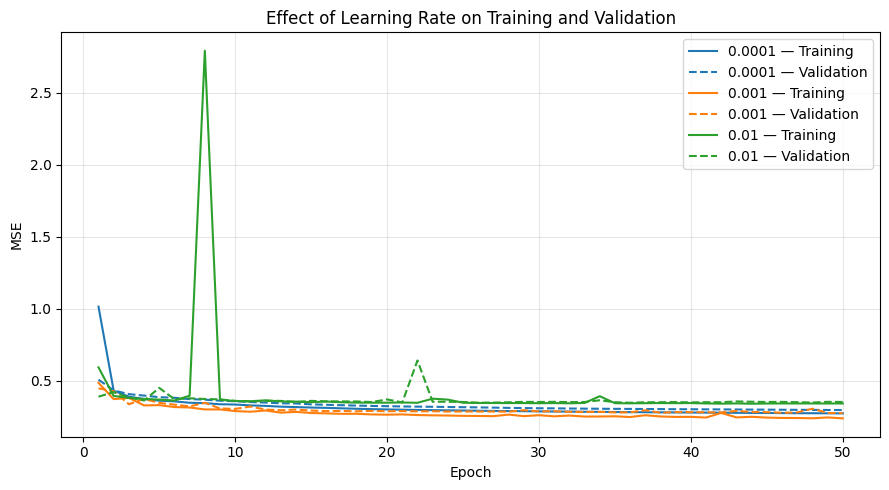

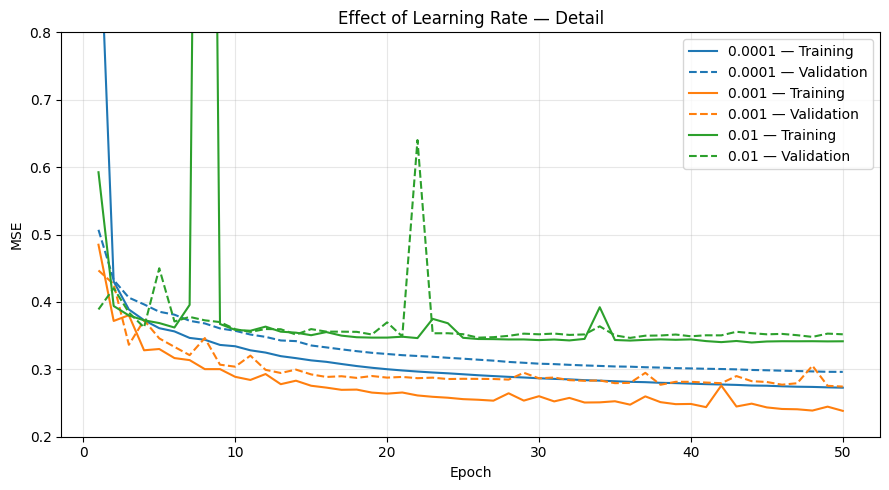

In [157]:
plot_comparison(
    histories_2,
    "Effect of Learning Rate on Training and Validation"
)

plot_comparison(
    histories_2,
    "Effect of Learning Rate — Detail",
    detail_ylim=(0.2, 0.8)
)

#### Problem 4 Graded Answers 

In [151]:
 # Your answer here
best_rate_row = learning_rate_results['val_mae'].idxmin()
a4a = learning_rate_results.loc[best_rate_row, "learning_rate"]                 # Learning rate that achieved the lowest validation MAE

In [152]:
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a4a = {a4a}")

a4a = 0.001


In [153]:
 # Your answer here

a4b = np.min(learning_rate_results['val_mae'])                    # replace 0 with an expression or float returning the lowest validation MAE among the three experiments.

In [154]:
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a4b = {a4b:.4f}")

a4b = 0.3403


## Problem 5 — Select a Configuration and Evaluate the Final Model [5 points]

In Problems 3 and 4, you used sequential hyperparameter tuning to select a batch size and learning rate. First, you selected a batch size while holding the learning rate fixed. Then, using that batch size, you compared several learning rates.

In this problem, you will train a new model using the selected configuration and evaluate its performance on the held-out test set.

### Train and Evaluate the Selected Configuration

1. **Select the training configuration**
   - Use the batch size selected in Problem 3 (`a3a`).
   - Use the learning rate selected in Problem 4 (`a4a`).
   - These settings were selected sequentially, so they are not guaranteed to be the globally optimal combination.

2. **Build and train a new model**
   - Use the same architecture as in Problems 1, 3, and 4.
   - Reset the random seed to `42` and initialize a new model.
   - Compile using Adam with the selected learning rate, MSE loss, and MAE as a metric.
   - Train for **50 epochs**, using the selected batch size and the original training partition.
   - Use the fixed validation set to monitor training.

3. **Evaluate the final model**
   - Evaluate the trained model on the validation set and report its MAE.
   - After the configuration is fixed, evaluate the model once on the held-out test set and report its MAE.
   - Compare the validation and test MAE values. Are they reasonably close? What does this suggest about generalization?

**Important:** Do not change the model configuration based on the test results. The test set is reserved for final evaluation, not model selection.

### Graded Answers

Set the following variables using the final trained model:

- `a5a`: **Validation MAE** of the final model.
- `a5b`: **Test MAE** of the final model.

Use computed expressions or variables rather than manually entering numerical results.

Be sure to run all the **Graded Answer** cells before submitting.


In [159]:
# Your code here; add additional code cells as needed
final_model = clone_model(baseline_model)

tf.keras.utils.set_random_seed(RANDOM_SEED)

final_epochs = 50


final_opt = Adam(learning_rate=a4a)

final_model.compile(
    loss='MSE',
    optimizer=final_opt,
    metrics=['MAE']
)

final_history = final_model.fit(
    X_train_scaled,
    y_train_arr,
    validation_data=(X_val_scaled,y_val_arr),
    epochs=final_epochs,
    batch_size=a3a,
    verbose=0
)

training_results = lr_model.evaluate(X_train_scaled, y_train_arr, verbose=0)
validation_results = lr_model.evaluate(X_val_scaled, y_val_arr, verbose=0)

training_results

[0.32274147868156433, 0.4169350862503052]

In [123]:
 # Your answer here

a5a = 0.0                         # Validation MAE of the final model

In [124]:
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a5a = {a5a:.4f}")

a5a = 0.0000


In [125]:
 # Your answer here

a5b = 0.0                          # Test MAE of the final model

In [126]:
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a5b = {a5b:.4f}")

a5b = 0.0000


## Problem 6: Multiple-Choice Questions [10 points]

For each question, select the **single best answer (1, 2, 3, or 4)** and assign it to the corresponding variable (`a6a` through `a6e`). Each question is worth **2 points**.


### Part A: Output Layer for Regression

Which output layer is appropriate for predicting median house value with a neural network?

1. One sigmoid neuron, which restricts predictions to values between 0 and 1.
2. One linear neuron, which can output a continuous numerical value.
3. Seven softmax neurons, one for each possible house-value category.
4. One ReLU output neuron, which guarantees that predictions are below the maximum house value.


In [127]:
# Your answer here.

a6a = 0       # Must be one of 1, 2, 3, 4

In [128]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a6a = {a6a}")

a6a = 0


### Part B: Parameters in a Dense Layer

A Dense layer receives 8 input features and has 64 neurons. How many trainable parameters does it contain, including biases?

1. 512
2. 64
3. 576
4. 640


In [129]:
# Your answer here.

a6b = 0       # Must be one of 1, 2, 3, 4

In [130]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a6b = {a6b}")

a6b = 0


### Part C: Mini-Batch Size and Computational Cost

In Problem 3, you trained several neural networks for the same number of epochs, changing only the mini-batch size. Smaller batch sizes generally required more training time.

Which explanation best accounts for this observation?

1. Smaller batches contain more training examples, so each update takes longer.
2. Smaller batches require more weight updates per epoch, increasing the computational overhead of training.
3. Smaller batches increase the number of trainable parameters in the network.
4. Smaller batches require the model to evaluate the validation set more frequently.



In [131]:
# Your answer here.

a6c = 0       # Must be one of 1, 2, 3, 4

In [132]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a6c = {a6c}")

a6c = 0


### Part D: Selecting a Final Configuration

Which statement best describes the proper use of validation and test data in Problem 5?

1. Choose the configuration that gives the lowest test MAE, then report that test result.
2. Choose settings using validation results, evaluate once on the test set, and do not revise settings based on the test result.
3. Choose the configuration with the lowest training MSE, because training loss is the most reliable measure of generalization.
4. Evaluate all configurations on the test set and average their test MAEs before selecting one.


In [133]:
# Your answer here.

a6d = 0       # Must be one of 1, 2, 3, 4

In [134]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a6d = {a6d}")

a6d = 0


### Part E: Mini-Batch Size and Computational Cost

In Problem 3, you compared neural networks trained with different mini-batch sizes for the same number of epochs.

Which statement best describes how to interpret the relationship between validation MAE and training time?

1. The batch size producing the lowest validation MAE is always the best choice, regardless of training time.
2. The batch size with the shortest training time should always be selected, even if its validation MAE is substantially worse.
3. A smaller batch size always produces better validation performance because it performs more weight updates.
4. Choosing a batch size involves balancing validation performance against computational cost; the best choice depends on the application's priorities.


In [135]:
# Your answer here.

a6e = 0       # Must be one of 1, 2, 3, 4

In [136]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a6e = {a6e}")

a6e = 0


## Problem 7 — Reflection Questions [10 points]

Answer the following questions using complete sentences and coherent paragraphs. Support your conclusions with results from your experiments where appropriate.

### Reflection 7.A — What Did the Training Experiments Teach You?

Compare the effects of mini-batch size and learning rate on neural-network training.

1. Describe **one important finding** from your batch-size experiments and **one important finding** from your learning-rate experiments. Support each with specific numerical results from your tables or learning curves.
2. Explain how these two hyperparameters influence the training process differently.
3. Why might a configuration that reduces training loss more quickly fail to produce the best validation performance?

Write **a coherent response of approximately 125–175 words** in `a7a`.

### Reflection 7.B — From Linear Regression to Neural Networks

In this homework, you trained a neural network to predict median house values using a single linear output neuron.

1. Explain how the hidden ReLU layers allow this network to represent relationships that ordinary linear regression cannot capture directly.
2. Explain why **MSE** is used as the training loss while **MAE** is useful for evaluating and interpreting predictions.
3. Identify **one important limitation** of your neural-network model or the California Housing dataset, and explain how it affects the interpretation of your results.

Write **a coherent response of approximately 125–175 words** in `a7b`.

In [137]:
a7a = """
Your answer here
"""

a7b = """
Your answer here
"""


In [138]:
# Graded Answers
# DO NOT change this cell in any way

print(f'a7a = {a7a}')

a7a = 
Your answer here



In [139]:
# Graded Answers
# DO NOT change this cell in any way

print(f'a7b = {a7b}')

a7b = 
Your answer here



## Submission Checklist

-  Run the entire notebook from a fresh kernel without errors.
-  Leave all required tables and plots visible, including the learning curves and the validation MAE versus training time plot.
-  Verify that all numeric answers are computed from your results, rather than manually entered constants.
-  Complete all answer variables: `a1a`–`a1c`, `a2a`–`a2c`, `a3a`–`a3b`, `a4a`–`a4b`, `a5a`–`a5b`, `a6a`–`a6e`, and `a7a`–`a7b`.
-  Verify that the test set was used only for the final evaluation in Problem 5.
-  Run all Graded Answer cells without editing them.
-  Submit the completed `.ipynb` notebook through Gradescope.
